# 01 — EDA dan Data Cleaning

**Tujuan:** memahami data sebelum modeling: tipe data, nilai hilang, masalah `TotalCharges`, distribusi target, dan fitur mana yang tampak berhubungan dengan churn. Notebook ini juga memeriksa potensi *data leakage*.

Semua angka di notebook ini dihitung oleh kode di sel-selnya. Logika cleaning ada di `src/data_cleaning.py` supaya bisa dipakai ulang oleh pipeline, aplikasi, dan unit test.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
import pandas as pd

from src.config import FIGURES_DIR, ID_COL, RAW_CSV, REPORTS_DIR, TARGET_COL
from src.data_cleaning import clean_data, load_raw

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Colors: slots 1-2 of the validated categorical palette; ink and grid stay neutral.
STAY, CHURN = "#2a78d6", "#eb6834"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Memuat data mentah

In [2]:
raw = load_raw()
print("shape:", raw.shape)
raw.head()

shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7,151.65,Yes


Saat dibaca dengan pengaturan default pandas, kolom mana yang tipenya tidak sesuai dugaan?

In [3]:
default_read = pd.read_csv(RAW_CSV)
default_read.dtypes.to_frame("dtype (default read)").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype (default read),str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,str,str


`TotalCharges` terbaca sebagai teks padahal isinya angka. Itu tanda ada nilai yang bukan angka di dalamnya. `SeniorCitizen` berupa 0/1, sedangkan kolom biner lain berupa Yes/No; ini hanya perbedaan format, bukan masalah.

## 2. Nilai hilang dan masalah `TotalCharges`

In [4]:
nan_default = default_read.isna().sum()
blank_strings = (raw.apply(lambda s: s.str.strip() == "")).sum()
pd.DataFrame({"NaN (default read)": nan_default, "blank string": blank_strings}).query("`NaN (default read)` > 0 or `blank string` > 0")

,NaN (default read),blank string
TotalCharges,0,11


In [5]:
blank_tc = raw["TotalCharges"].str.strip() == ""
raw.loc[blank_tc, [ID_COL, "tenure", "MonthlyCharges", "TotalCharges", TARGET_COL]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.0,,No
5218,2923-ARZLG,0,19.7,,No
6670,4075-WKNIU,0,73.35,,No


In [6]:
print("blank TotalCharges:", blank_tc.sum())
print("rows with tenure == 0:", (raw["tenure"] == "0").sum())
print("blank TotalCharges AND tenure == 0:", (blank_tc & (raw["tenure"] == "0")).sum())

blank TotalCharges: 11
rows with tenure == 0: 11
blank TotalCharges AND tenure == 0: 11


**Keputusan: isi `TotalCharges` kosong dengan 0.**

- Semua baris kosong adalah pelanggan dengan `tenure = 0`, yaitu pelanggan baru yang belum pernah ditagih. Jadi nilai sebenarnya memang 0, bukan "tidak diketahui".
- Ini aturan deterministik per baris (tidak menghitung statistik apa pun dari data), sehingga aman dijalankan sebelum split dan tidak menimbulkan leakage. Imputasi berbasis mean/median justru harus di-fit di data train saja, dan itu dikerjakan di pipeline Fase 2.
- Alternatifnya menghapus 11 baris. Tidak dipilih karena pelanggan baru tetap ada di dunia nyata, dan aplikasi Streamlit nanti harus bisa menerima `tenure = 0`.
- Kalau suatu saat ada `TotalCharges` kosong untuk `tenure > 0`, `clean_data` membiarkannya NaN supaya ditangani imputer di pipeline.

In [7]:
df = clean_data(raw)
print("NaN after cleaning:", int(df.isna().sum().sum()))
print("TotalCharges of the former blanks:", df.loc[blank_tc, "TotalCharges"].unique())
df.dtypes.to_frame("dtype (clean)").T

NaN after cleaning: 0
TotalCharges of the former blanks: [0.]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
dtype (clean),str,str,int64,str,str,int64,str,str,str,str,str,str,str,str,str,str,str,str,float64,float64,int64


## 3. Duplikat

In [8]:
print("duplicate customerID:", df[ID_COL].duplicated().sum())
dup_features = df.drop(columns=ID_COL).duplicated(keep=False)
print("rows whose features+target are identical to another row:", dup_features.sum())
df.loc[dup_features].drop(columns=ID_COL).value_counts().head(5).to_frame("count")

duplicate customerID: 0
rows whose features+target are identical to another row: 42


count
gender SeniorCitizen Partner Dependents tenure PhoneService MultipleLines InternetService OnlineSecurity      OnlineBackup        DeviceProtection    TechSupport         StreamingTV         StreamingMovies     Contract       PaperlessBilling PaymentMethod MonthlyCharges TotalCharges Churn       
Male   0             No      No         1      Yes          No            No              No internet service No internet service No internet service No internet service No internet service No internet service Month-to-month No               Mailed check  20.20          20.20        0          3
                                                                                                                                                                                                                                                                20.05          20.05        0          3
                                                                                                                                                                                                                                                                20.15          20.15        1          2
Female 0             No      No         1      Yes          No            No              No internet service No internet service No internet service No internet service No internet service No internet service Month-to-month No               Mailed check  19.55          19.55        0          2
Male   0             No      No         1      Yes          No            DSL             No                  No                  No                  No                  No                  No                  Month-to-month Yes              Mailed check  45.70          45.70        1          2

Tidak ada `customerID` ganda. Ada 42 baris milik pelanggan berbeda yang profilnya (fitur dan target) sama persis dengan baris lain. Profil yang paling sering berulang adalah profil sederhana: tenure 1 bulan, kontrak bulanan, paket dasar. Karena `customerID`-nya berbeda, baris-baris ini dianggap pelanggan yang sah dan **tidak dihapus**.

Catatan kecil: kalau satu baris kembar masuk train dan kembarannya masuk test, model "sudah pernah melihat" baris test itu. Dengan 42 dari 7.043 baris (sekitar 0,6%), efeknya pada metrik diperkirakan kecil, tetapi tetap disebut sebagai keterbatasan.

## 4. Distribusi target

In [9]:
counts = df[TARGET_COL].value_counts().sort_index()
share = counts / counts.sum()
summary = pd.DataFrame({"count": counts, "share": share.round(4)}, index=[0, 1]).rename(index={0: "No churn", 1: "Churn"})
summary

,count,share
No churn,5174,0.7346
Churn,1869,0.2654


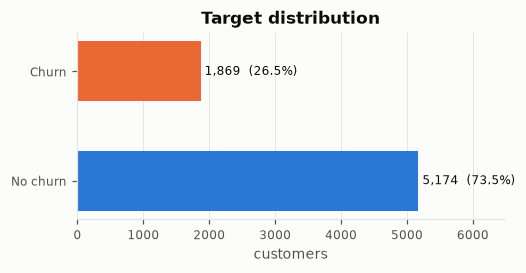

In [10]:
fig, ax = plt.subplots(figsize=(5, 2.2))
labels = ["No churn", "Churn"]
ax.barh(labels, counts.values, color=[STAY, CHURN], height=0.55)
for y, (n, p) in enumerate(zip(counts.values, share.values)):
    ax.text(n + 60, y, f"{n:,}  ({p:.1%})", va="center", fontsize=8, color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("customers")
ax.grid(axis="y", visible=False)
ax.set_title("Target distribution")
save(fig, "01_target_distribution")
plt.show()

Data **tidak seimbang**: kelas churn jauh lebih sedikit. Konsekuensinya:

- Akurasi menyesatkan. Model yang selalu menebak "tidak churn" sudah mendapat akurasi setara proporsi kelas mayoritas tanpa menemukan satu pun pelanggan churn. Karena itu evaluasi memakai PR-AUC, recall, precision, dan F1.
- Split train/test dan cross-validation harus **stratified** supaya proporsi churn sama di tiap bagian.

## 5. Fitur numerik

In [11]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df.groupby(TARGET_COL)[num_cols].describe().T.round(2)

Churn                       0        1
tenure         count  5174.00  1869.00
               mean     37.57    17.98
               std      24.11    19.53
               min       0.00     1.00
               25%      15.00     2.00
               50%      38.00    10.00
               75%      61.00    29.00
               max      72.00    72.00
MonthlyCharges count  5174.00  1869.00
               mean     61.27    74.44
               std      31.09    24.67
               min      18.25    18.85
               25%      25.10    56.15
               50%      64.43    79.65
               75%      88.40    94.20
               max     118.75   118.35
TotalCharges   count  5174.00  1869.00
               mean   2549.91  1531.80
               std    2329.95  1890.82
               min       0.00    18.85
               25%     572.90   134.50
               50%    1679.52   703.55
               75%    4262.85  2331.30
               max    8672.45  8684.80

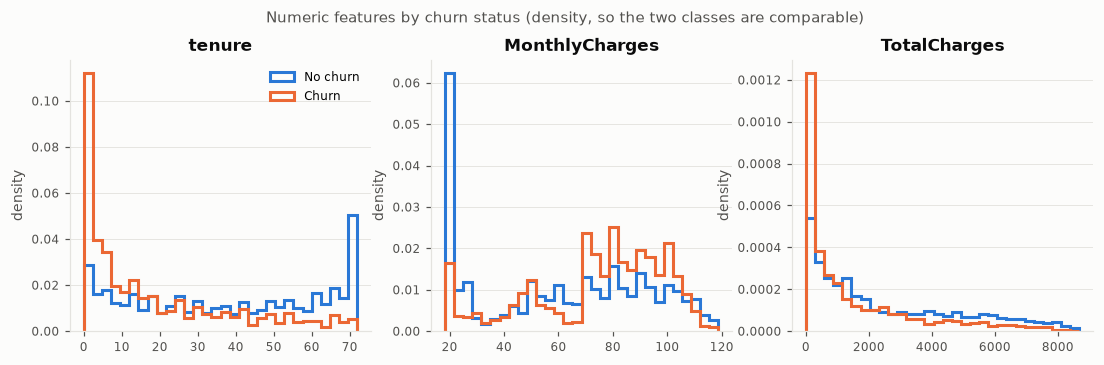

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, num_cols):
    bins = np.histogram_bin_edges(df[col], bins=30)
    for value, color, label in [(0, STAY, "No churn"), (1, CHURN, "Churn")]:
        ax.hist(df.loc[df[TARGET_COL] == value, col], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=label)
    ax.set_title(col)
    ax.set_ylabel("density")
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper right")
fig.suptitle("Numeric features by churn status (density, so the two classes are comparable)", fontsize=10, color=INK_2, y=1.02)
save(fig, "02_numeric_by_churn")
plt.show()

## 6. Churn rate per kategori

In [13]:
cat_cols = [c for c in df.columns if c not in num_cols + [ID_COL, TARGET_COL]]
overall_rate = df[TARGET_COL].mean()

rows = []
for col in cat_cols:
    g = df.groupby(col)[TARGET_COL].agg(["mean", "size"])
    for level, r in g.iterrows():
        rows.append({"feature": col, "level": str(level), "churn_rate": r["mean"], "n": int(r["size"])})
rates = pd.DataFrame(rows)
rates["lift_vs_overall"] = rates["churn_rate"] / overall_rate
rates.round(4).to_csv(REPORTS_DIR / "eda_churn_rate_by_category.csv", index=False)

spread = rates.groupby("feature")["churn_rate"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
print(f"overall churn rate: {overall_rate:.4f}")
spread.rename("max - min churn rate across levels").round(4).to_frame()

overall churn rate: 0.2654


,max - min churn rate across levels
feature,
Contract,0.3988
InternetService,0.3449
OnlineSecurity,0.3436
TechSupport,0.3423
OnlineBackup,0.3252
DeviceProtection,0.3172
PaymentMethod,0.3004
StreamingMovies,0.2628
StreamingTV,0.2612


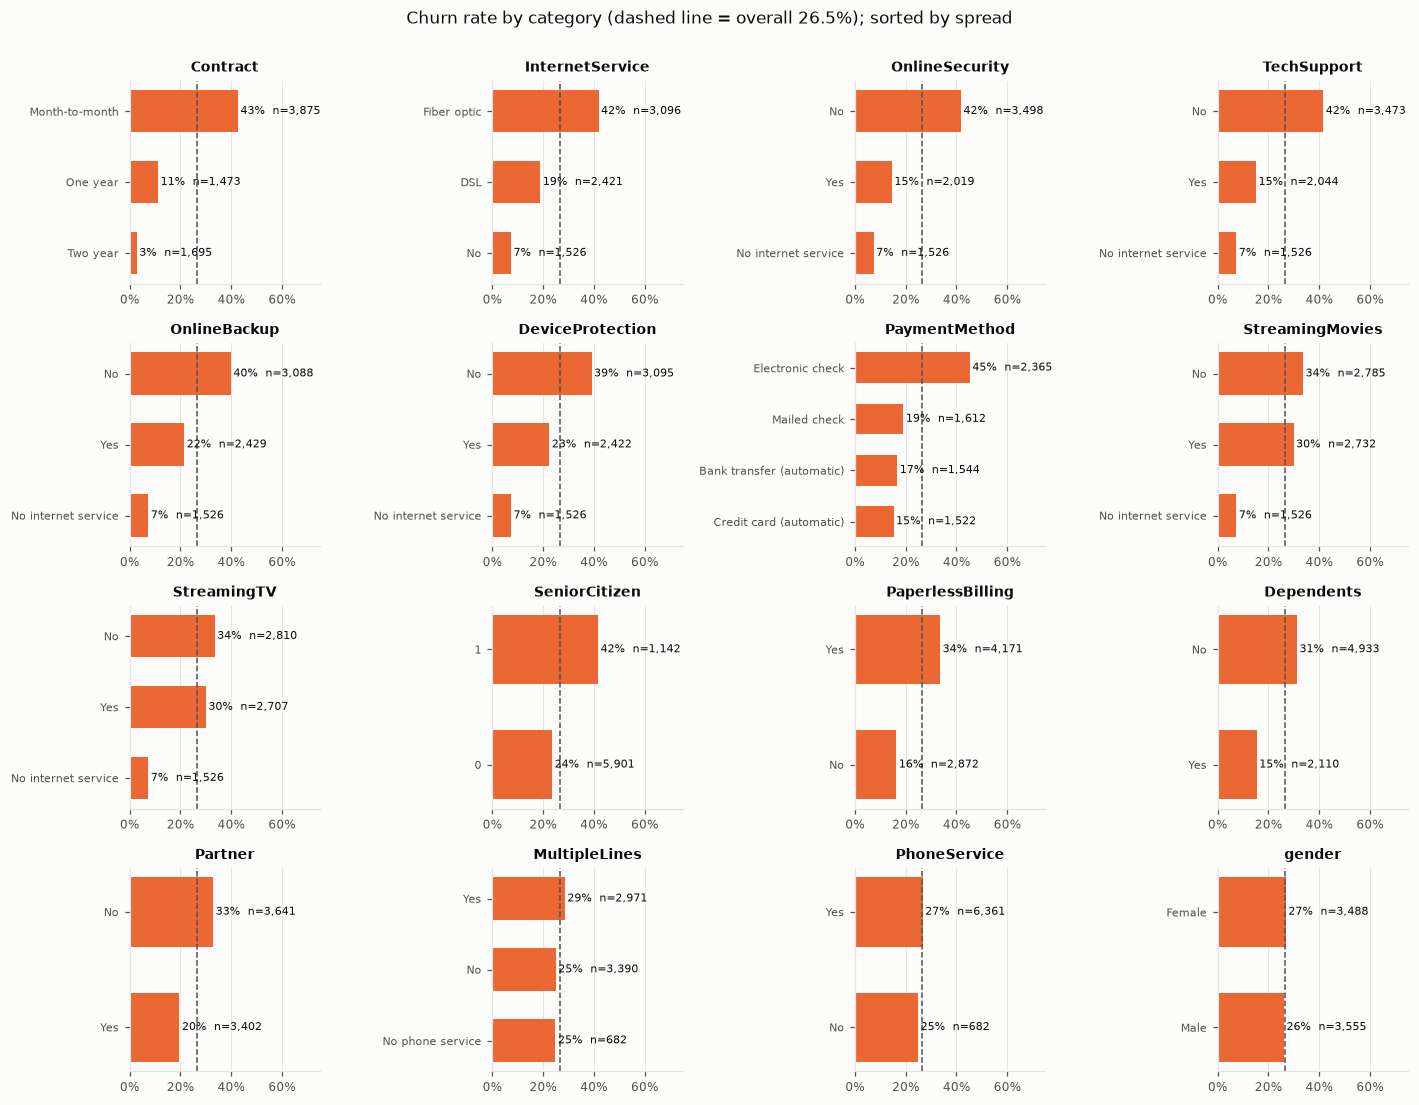

In [14]:
order = spread.index.tolist()
fig, axes = plt.subplots(4, 4, figsize=(13, 10))
for ax, col in zip(axes.flat, order):
    sub = rates[rates["feature"] == col].sort_values("churn_rate")
    ax.barh(sub["level"], sub["churn_rate"], color=CHURN, height=0.6)
    ax.axvline(overall_rate, color=INK_2, linewidth=1, linestyle="--")
    for y, (rate, n) in enumerate(zip(sub["churn_rate"], sub["n"])):
        ax.text(rate + 0.01, y, f"{rate:.0%}  n={n:,}", va="center", fontsize=7, color=INK)
    ax.set_xlim(0, 0.75)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_title(col, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=7)
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
fig.suptitle(f"Churn rate by category (dashed line = overall {overall_rate:.1%}); sorted by spread", fontsize=11, color=INK, y=1.0)
fig.tight_layout()
save(fig, "03_churn_rate_by_category")
plt.show()

## 7. Hubungan antar fitur dan pemeriksaan leakage

In [15]:
df[num_cols + [TARGET_COL]].corr(method="spearman").round(3)

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000,0.276,0.890,-0.367
MonthlyCharges,0.276,1.000,0.638,0.185
TotalCharges,0.890,0.638,1.000,-0.230
Churn,-0.367,0.185,-0.230,1.000


In [16]:
approx_total = df["tenure"] * df["MonthlyCharges"]
billed = df["tenure"] > 0
rel_gap = ((df["TotalCharges"] - approx_total).abs() / approx_total)[billed]
print("Pearson corr(TotalCharges, tenure*MonthlyCharges):", round(np.corrcoef(df["TotalCharges"], approx_total)[0, 1], 4))
print("median relative gap:", round(rel_gap.median(), 4), "| 95th percentile:", round(rel_gap.quantile(0.95), 4))

Pearson corr(TotalCharges, tenure*MonthlyCharges): 0.9996
median relative gap: 0.02 | 95th percentile: 0.1032


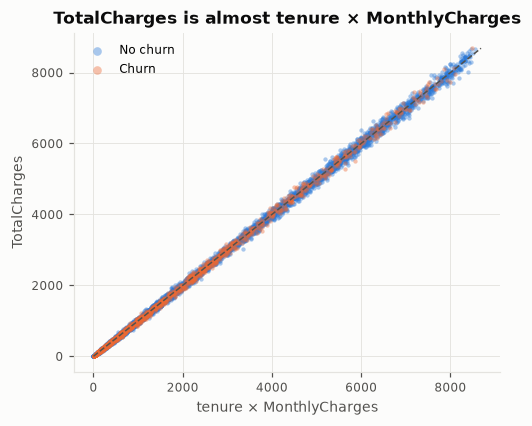

In [17]:
fig, ax = plt.subplots(figsize=(5, 4))
for value, color, label in [(0, STAY, "No churn"), (1, CHURN, "Churn")]:
    m = df[TARGET_COL] == value
    ax.scatter(approx_total[m], df.loc[m, "TotalCharges"], s=8, alpha=0.4, color=color, label=label, linewidths=0)
lim = [0, max(approx_total.max(), df["TotalCharges"].max())]
ax.plot(lim, lim, color=INK_2, linewidth=1, linestyle="--")
ax.set_xlabel("tenure × MonthlyCharges")
ax.set_ylabel("TotalCharges")
ax.set_title("TotalCharges is almost tenure × MonthlyCharges")
ax.legend(loc="upper left", markerscale=2)
save(fig, "04_totalcharges_vs_product")
plt.show()

In [18]:
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = df["InternetService"] == "No"
print("InternetService == 'No':", no_internet.sum())
print("  of which all add-ons == 'No internet service':", (df.loc[no_internet, internet_addons] == "No internet service").all(axis=1).sum())
print("'No internet service' appearing while InternetService != 'No':", (df.loc[~no_internet, internet_addons] == "No internet service").any(axis=1).sum())
no_phone = df["PhoneService"] == "No"
print("PhoneService == 'No':", no_phone.sum(), "| MultipleLines == 'No phone service':", (df["MultipleLines"] == "No phone service").sum())

InternetService == 'No': 1526
  of which all add-ons == 'No internet service': 1526
'No internet service' appearing while InternetService != 'No': 0
PhoneService == 'No': 682 | MultipleLines == 'No phone service': 682


**Catatan leakage dan redundansi:**

- **`customerID`** hanya pengenal. Tidak punya arti prediktif dan bisa membuat model menghafal baris, jadi dibuang sebelum modeling.
- **`TotalCharges`** hampir sama dengan `tenure × MonthlyCharges` (lihat korelasi dan scatter di atas). Ini **bukan leakage**, karena nilainya diketahui sebelum pelanggan churn, tetapi fiturnya **redundan**. Logistic Regression bisa terpengaruh multikolinearitas (koefisien sulit ditafsirkan); model pohon tidak terlalu terpengaruh. Untuk Fase 2 fitur ini tetap disertakan dan dampaknya dicek di Fase 3.
- **Kategori "No internet service" / "No phone service"** sepenuhnya ditentukan oleh `InternetService` dan `PhoneService` (cek di atas). Informasinya dobel, tetapi tidak salah. One-hot encoding akan menghasilkan kolom yang identik; ini dicatat untuk Fase 2.
- **Potensi leakage yang tidak bisa dicek:** dataset tidak punya tanggal. Kita tidak tahu apakah `tenure`, `Contract`, atau `TotalCharges` diambil *sebelum* atau *sesudah* pelanggan churn. Kalau diambil sesudahnya, misalnya `tenure` berhenti bertambah saat pelanggan keluar, model di dunia nyata bisa lebih lemah dari hasil di sini. Ini dicatat sebagai keterbatasan.

## 8. Ringkasan Fase 1

**Kualitas data**

- 7.043 baris × 21 kolom, tidak ada `customerID` ganda.
- Satu-satunya nilai hilang: 11 `TotalCharges` kosong, semuanya pelanggan `tenure = 0`, lalu diisi 0 (aturan deterministik, aman dari leakage).
- Target tidak seimbang: 1.869 churn (26,5%) vs 5.174 tidak churn (73,5%). Evaluasi memakai PR-AUC/recall/precision, dan split harus stratified.

**Pola yang paling menonjol** (hubungan satu-satu fitur dengan churn, belum tentu sebab-akibat):

| Pola | Churn rate |
|---|---|
| Kontrak bulanan vs kontrak 2 tahun | 42,7% vs 2,8% |
| Bayar dengan *electronic check* vs kartu kredit otomatis | 45,3% vs 15,2% |
| Internet *fiber optic* vs DSL | 41,9% vs 19,0% |
| Tanpa *OnlineSecurity* vs dengan *OnlineSecurity* | 41,8% vs 14,6% |
| Tanpa *TechSupport* vs dengan *TechSupport* | 41,6% vs 15,2% |
| Senior citizen vs bukan | 41,7% vs 23,6% |
| Perempuan vs laki-laki | 26,9% vs 26,2% (hampir tidak berbeda) |

- **Tenure:** median tenure pelanggan yang churn 10 bulan, sedangkan yang bertahan 38 bulan. Risiko churn paling tinggi di bulan-bulan awal.
- **Tagihan bulanan:** median `MonthlyCharges` pelanggan churn 79,65 vs 64,43 untuk yang bertahan.

Fitur-fitur ini kemungkinan saling berkaitan (misalnya pelanggan fiber optic mungkin lebih sering memakai kontrak bulanan). Model multivariat di Fase 3 dan SHAP di Fase 6 akan memisahkan pengaruh masing-masing.

**Bekal untuk Fase 2**

- Buang `customerID`.
- `TotalCharges` hampir identik dengan `tenure × MonthlyCharges` (korelasi Pearson 0,9996): redundan tapi bukan leakage.
- Kategori "No internet service" dan "No phone service" dobel dengan `InternetService` / `PhoneService`.
- Data tidak punya tanggal, jadi validasi berbasis waktu tidak bisa dilakukan.